### Wehret den Wildschweinen! – Lösung Schritt für Schritt

*36. Bundeswettbewerb Informatik (2017/2018), 2. Runde, Aufgabe 2*

Ein Wald ist von Wildschweinen bevölkert. Sie fallen regelmäßig auf einem südlich des Waldes liegenden Acker ein. Zwischen Wald und
Acker liegt ein rechteckiges, hügeliges Brachland, das im Osten und im Westen abgezäunt ist.

Der Besitzer des gesamten Geländes ist es leid, dass die Wildschweine ständig seinen Acker verwüsten. Er will dafür sorgen, dass sie
nicht vom Wald auf den Acker gelangen können. Dafür macht er sich zunutze, dass Wildschweine nicht in der Lage sind, größere Steigungen
zu überwinden. Er kann die Wildschweine also davon abhalten, das Brachland zu überqueren, indem er an gezielten Stellen dessen
Landschaft so verändert, dass sie für ein Wildschwein zu steil abfällt oder ansteigt.

Zur Vereinfachung reduziert er die Landschaft auf Planquadrate und die möglichen Wege der Wildschweine auf solche, deren Abschnitte
stets vom Zentrum eines Planquadrats zum Zentrum eines in nördlicher, südlicher, östlicher oder westlicher Richtung benachbarten
Planquadrats verlaufen. Er muss jetzt erreichen, dass auf jedem solchen Weg von der Nordgrenze bis zur Südgrenze der Brache mindestens
einmal der Höhenunterschied zwischen aufeinander folgenden Planquadraten mindestens 1 m beträgt. Dazu kann er Erde von einem
Planquadrat zu einem benachbarten Planquadrat bringen lassen, wodurch die Höhe des ersten Planquadrats fällt und die des zweiten
Planquadrats um genauso viel wächst. Da solche Erdarbeiten aber teuer sind, ist er bestrebt, diese Maßnahme so wenig wie möglich
einzusetzen.

#### Aufgabe

Schreibe ein Programm, das eine Matrix mit den Höhen der Planquadrate des Brachlands einliest und kostengünstigste Erdarbeiten
vorschlägt, die jeden Weg von der Nordgrenze bis zur Südgrenze für Wildschweine unpassierbar werden lassen. Gehe dabei davon aus, dass
es genau h Euro kostet, h cm Erde von einem Planquadrat zu einem benachbarten Planquadrat bringen zu lassen.

Wende dein Programm auf die Beispiele an, die du auf der BWINF-Website findest, und dokumentiere die Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `wildschwein1.txt` bis `wildschwein5.txt`. Eine Formatbeschreibung gibt es nicht; aus den Dateien liest
man ab: Die erste Zeile enthält die Seitenlänge `n` der quadratischen Brache, danach folgen `n` Zeilen mit je `n` Höhen in Metern (mit drei
Nachkommastellen, also auf den Millimeter genau). Die erste Zeile liegt am Wald (Nordgrenze), die letzte am Acker (Südgrenze).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Breitensuche** auf einem Gitter: Von allen Feldern am Nordrand aus findet man alle Felder, die ein Wildschwein erreichen kann. Damit
  bauen wir einen **Schiedsrichter**, der jeden Vorschlag prüft.
- **Den Spieß umdrehen (Dualität):** Statt alle Wege der Wildschweine zu versperren, bauen wir eine zusammenhängende **Sperre** aus
  steilen Linien vom West- zum Ostrand. Die Linien zwischen den Planquadraten bilden einen Graphen, dessen Knoten die **Ecken** der
  Planquadrate sind.
- **Dijkstra-Algorithmus** für den billigsten Weg in einem Graphen mit Kantengewichten, hier für die billigste Sperre.
- **Zusammenhangskomponenten und 2-Färbung:** Felder, die über Linien der Sperre verbunden sind, beeinflussen sich gegenseitig. Man
  findet sie mit einer Breitensuche und färbt sie dabei abwechselnd „hoch“ und „tief“.
- **Gierige Verfahren und Zufall:** Eine Schätzung der Kosten ist nicht genau; viele leicht verschiedene Versuche finden oft etwas
  Besseres als ein einziger.
- **Untere Schranke:** Eine einfache Überlegung zeigt, wie viel es **mindestens** kostet. So sehen wir, wie gut unsere Lösungen sind.

**Nützliche Funktionen und Bibliotheken**
- `heapq.heappush` und `heapq.heappop` für die Warteschlange von Dijkstra: `heappop` gibt immer das kleinste Element zurück.
- `collections.deque` mit `append` und `popleft` als Warteschlange für die Breitensuche.
- `random.Random(zahl)`: ein Zufallsgenerator, der bei gleicher Zahl immer dieselben Zufallszahlen liefert; `zufall.uniform(a, b)` gibt
  eine Kommazahl zwischen `a` und `b`.
- `liste.sort()` sortiert auch Tupel: zuerst nach dem ersten Eintrag, bei Gleichstand nach dem zweiten.
- `matplotlib.pyplot` mit `imshow` zum Zeichnen der Höhen als Graustufenbild (hell ist hoch).

## Die Idee in Worten

1. **Kritische Linien.** Zwischen zwei benachbarten Planquadraten liegt eine Linie. Ist der Höhenunterschied dort mindestens 1 m, kommt
   kein Wildschwein darüber; die Linie heißt **kritisch**. Schaufelt man `w` Meter Erde vom niedrigeren zum höheren Feld, sinkt das eine
   um `w` und das andere steigt um `w`: Der Unterschied `Δ` wächst um `2w`. Eine Linie wird also für `(1 - Δ) / 2` kritisch.
2. **Die Sperre.** Die Wildschweine kommen genau dann nicht durch, wenn kritische Linien eine zusammenhängende Kette vom Westzaun zum
   Ostzaun bilden (eine Ecke genügt als Verbindung, denn schräg laufen Wildschweine nicht). Diese Kette nennen die Lösungshinweise einen
   **kritischen Pfad**.
3. **Version 1:** eine gerade Sperre quer durch die Brache, in der Zeile, in der es am billigsten ist.
4. **Version 2 (wie in den Lösungshinweisen):** Mit Dijkstra den Pfad suchen, bei dem die Summe der Kosten der einzelnen Linien am
   kleinsten ist. Das ist nur eine Schätzung: Liegen zwei Linien am selben Feld, helfen oder stören sich ihre Erdarbeiten.
5. **Version 3:** die Erdarbeiten für denselben Pfad geschickter ausführen.
6. **Version 4:** viele Pfade mit zufällig verfälschten Gewichten ausprobieren und den besten nehmen.
7. **Zum Schluss** berechnet MiniZinc für unseren besten Pfad die bestmöglichen Erdarbeiten.

Die Kosten geben wir in Metern Erde an: 1 m Erde (100 cm) kostet 100 Euro.

## Schritt 1: Einlesen und Zeichnen

Die Höhen speichern wir als Liste von Zeilen: `h[r][c]` ist die Höhe des Feldes in Zeile `r` (0 ist die Nordgrenze) und Spalte `c` (0
ist der Westzaun). Ein Feld schreiben wir als Tupel `(r, c)`. `zeichne` malt die Höhen als Graustufenbild und, wenn angegeben, die Linien
einer Sperre in Rot.

wildschwein1.txt: 20 x 20 Planquadrate, Höhen von 2.172 m bis 8.817 m
wildschwein2.txt: 12 x 12 Planquadrate, Höhen von 2.000 m bis 2.000 m
wildschwein3.txt: 10 x 10 Planquadrate, Höhen von 2.000 m bis 4.100 m
wildschwein4.txt: 15 x 15 Planquadrate, Höhen von 3.005 m bis 3.999 m
wildschwein5.txt: 20 x 20 Planquadrate, Höhen von 0.330 m bis 5.903 m


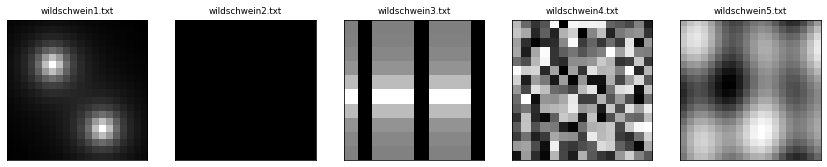

In [ ]:
import heapq
import random
from collections import deque
import matplotlib.pyplot as plt

EPS = 1e-9          # Toleranz für Vergleiche mit Kommazahlen


def datei(nr):
    return 'beispieldaten/wildschwein%d.txt' % nr


def lies(dateiname):
    with open(dateiname, encoding='utf-8') as f:
        zahlen = f.read().split()
    n = int(zahlen[0])
    h = []
    for r in range(n):
        zeile = []
        for c in range(n):
            zeile.append(float(zahlen[1 + r * n + c]))
        h.append(zeile)
    return h


def hoehe(h, feld):
    return h[feld[0]][feld[1]]


def zeichne(achse, h, titel, linien=None):
    achse.imshow(h, cmap='gray')
    if linien is not None:
        for a, b in linien:
            if a[1] == b[1]:                  # Felder übereinander: waagerechte Linie
                y = max(a[0], b[0]) - 0.5
                achse.plot([a[1] - 0.5, a[1] + 0.5], [y, y], color='red', linewidth=2.5)
            else:                             # Felder nebeneinander: senkrechte Linie
                x = max(a[1], b[1]) - 0.5
                achse.plot([x, x], [a[0] - 0.5, a[0] + 0.5], color='red', linewidth=2.5)
    achse.set_title(titel, fontsize=9)
    achse.set_xticks([])
    achse.set_yticks([])


felder = {}
for nr in range(1, 6):
    felder[nr] = lies(datei(nr))
    h = felder[nr]
    kleinste = min(min(zeile) for zeile in h)
    groesste = max(max(zeile) for zeile in h)
    print('wildschwein%d.txt: %2d x %2d Planquadrate, Höhen von %.3f m bis %.3f m' % (nr, len(h), len(h), kleinste, groesste))

fig, achsen = plt.subplots(1, 5, figsize=(15, 3.4))
for nr in range(1, 6):
    zeichne(achsen[nr - 1], felder[nr], 'wildschwein%d.txt' % nr)
plt.show()

`wildschwein1.txt` hat zwei spitze Hügel, `wildschwein2.txt` ist ganz flach (das Bild ist einfarbig), `wildschwein3.txt` hat drei flache
Rinnen von Nord nach Süd (Spalten 1, 5 und 9), dazwischen steigt das Land zur Mitte (Zeile 5) hin an, `wildschwein4.txt` ist zufällig uneben mit kleinen Unterschieden und
`wildschwein5.txt` eine Wellenlandschaft.

## Schritt 2: Was kostet eine Linie?

Zwei Felder mit den Höhen `a < b` sollen einen Unterschied von mindestens 1 m bekommen. Bringen wir `w` Meter Erde vom niedrigeren zum
höheren Feld, haben sie danach die Höhen `a - w` und `b + w`, der Unterschied ist `(b - a) + 2w`. Aus `(b - a) + 2w ≥ 1` folgt
`w ≥ (1 - (b - a)) / 2`. Ist der Unterschied schon mindestens 1 m, kostet die Linie nichts. Erde in die andere Richtung zu bringen wäre
schlechter: Dann müsste man erst den vorhandenen Unterschied ausgleichen.

`arbeit_fuer_linie` gibt die Erdarbeit für eine einzelne Linie als Tupel `(von, nach, menge)` zurück.

In [ ]:
def kosten_linie(h, a, b):
    unterschied = abs(hoehe(h, a) - hoehe(h, b))
    return max(0.0, (1 - unterschied) / 2)


def arbeit_fuer_linie(h, a, b):
    if hoehe(h, a) > hoehe(h, b):
        a, b = b, a                           # a ist jetzt das niedrigere Feld
    return (a, b, kosten_linie(h, a, b))


klein = [[2.0, 2.3],
         [2.0, 3.5]]
for a, b in (((0, 0), (0, 1)), ((0, 1), (1, 1))):
    von, nach, menge = arbeit_fuer_linie(klein, a, b)
    print('von', von, 'nach', nach, round(menge, 3), 'm')

von (0, 0) nach (0, 1) 0.35 m
von (0, 1) nach (1, 1) 0.0 m


Zwischen 2,0 m und 2,3 m bringt man 0,35 m Erde vom linken zum rechten Feld (danach 1,65 m und 2,65 m). Die Linie zwischen 2,3 m und
3,5 m ist schon kritisch und kostet nichts.

## Schritt 3: Der Schiedsrichter

Bevor wir Lösungen suchen, bauen wir eine unabhängige Probe. `schiedsrichter` führt eine Liste von Erdarbeiten aus. Dabei prüft er, dass
jede Arbeit zwischen Nachbarfeldern stattfindet und die Menge nicht negativ ist, und zählt die Kosten zusammen. Danach lässt er die
Wildschweine laufen: Eine **Breitensuche** beginnt bei allen Feldern der Nordgrenze und geht zu jedem Nachbarfeld, dessen Höhe sich um
weniger als 1 m unterscheidet. Erreicht sie die Südgrenze, ist die Brache nicht gesperrt. Wegen der Kommazahlen erlauben wir eine winzige
Toleranz `EPS` (ein milliardstel Meter).

In [ ]:
def schiedsrichter(h, arbeiten):
    """Gibt (gesperrt, kosten, neue Höhen) zurück."""
    n = len(h)
    neu = []
    for zeile in h:
        neu.append(zeile[:])                  # Kopie, die Eingabe bleibt unverändert
    kosten = 0
    for von, nach, menge in arbeiten:
        if menge < 0 or abs(von[0] - nach[0]) + abs(von[1] - nach[1]) != 1:
            return False, None, None
        neu[von[0]][von[1]] -= menge
        neu[nach[0]][nach[1]] += menge
        kosten += menge
    erreicht = set()
    warteschlange = deque()
    for c in range(n):
        erreicht.add((0, c))
        warteschlange.append((0, c))
    while warteschlange:
        r, c = warteschlange.popleft()
        if r == n - 1:
            return False, kosten, neu         # ein Wildschwein ist am Acker
        for rr, cc in ((r + 1, c), (r - 1, c), (r, c + 1), (r, c - 1)):
            if 0 <= rr < n and 0 <= cc < n and (rr, cc) not in erreicht:
                if abs(neu[rr][cc] - neu[r][c]) < 1 - EPS:
                    erreicht.add((rr, cc))
                    warteschlange.append((rr, cc))
    return True, kosten, neu


for nr in range(1, 6):
    print('wildschwein%d.txt ohne Erdarbeiten gesperrt:' % nr, schiedsrichter(felder[nr], [])[0])

wildschwein1.txt ohne Erdarbeiten gesperrt: False
wildschwein2.txt ohne Erdarbeiten gesperrt: False
wildschwein3.txt ohne Erdarbeiten gesperrt: False
wildschwein4.txt ohne Erdarbeiten gesperrt: False
wildschwein5.txt ohne Erdarbeiten gesperrt: False


## Schritt 4: Version 1 – eine gerade Sperre

Die einfachste Sperre ist eine gerade Linie quer durch die Brache, zwischen den Zeilen `r` und `r + 1`. Jede ihrer Linien liegt zwischen
zwei Feldern derselben Spalte, und jedes Feld gehört zu genau einer dieser Linien. Die Erdarbeiten stören sich also nicht, und die Kosten
sind genau die Summe der einzelnen Linien. Wir probieren alle Zeilen und nehmen die billigste.

In [ ]:
def gerade_sperre(h):
    n = len(h)
    beste = None
    for r in range(n - 1):
        arbeiten = []
        kosten = 0
        for c in range(n):
            arbeit = arbeit_fuer_linie(h, (r, c), (r + 1, c))
            if arbeit[2] > 0:
                arbeiten.append(arbeit)
                kosten += arbeit[2]
        if beste is None or kosten < beste[0] - EPS:
            beste = (kosten, r, arbeiten)
    return beste


ergebnis_v1 = {}
for nr in range(1, 6):
    kosten, r, arbeiten = gerade_sperre(felder[nr])
    gesperrt, kosten_sr, neu = schiedsrichter(felder[nr], arbeiten)
    ergebnis_v1[nr] = kosten_sr
    print('wildschwein%d.txt: zwischen Zeile %2d und %2d, %.4f m Erde, Schiedsrichter: %s' % (nr, r, r + 1, kosten_sr, gesperrt))

wildschwein1.txt: zwischen Zeile  4 und  5, 7.0880 m Erde, Schiedsrichter: True
wildschwein2.txt: zwischen Zeile  0 und  1, 6.0000 m Erde, Schiedsrichter: True
wildschwein3.txt: zwischen Zeile  4 und  5, 3.0750 m Erde, Schiedsrichter: True
wildschwein4.txt: zwischen Zeile  5 und  6, 4.1715 m Erde, Schiedsrichter: True
wildschwein5.txt: zwischen Zeile 12 und 13, 4.6320 m Erde, Schiedsrichter: True


## Schritt 5: Wie gut ist das? Eine untere Schranke

Jede Sperre vom West- zum Ostzaun muss jede Spalte einmal überqueren, enthält also in **jeder Spalte** eine waagerechte Linie. Diese
Linie liegt zwischen zwei Feldern der Spalte, deren Höhen sich zusammen um mindestens `1 - Δ` ändern müssen. Jeder Meter Erde, den man
bewegt, ändert die Höhen von zwei Feldern um je einen Meter, also die Summe aller Höhenänderungen um höchstens 2 m. Da die Spalten
verschiedene Felder haben, kostet jede Lösung **mindestens** die Summe über alle Spalten von `min (1 - Δ) / 2`: In jeder Spalte zählt
nur die billigste waagerechte Linie.

In [ ]:
def untere_schranke(h):
    n = len(h)
    summe = 0
    for c in range(n):
        billigste = None
        for r in range(n - 1):
            k = kosten_linie(h, (r, c), (r + 1, c))
            if billigste is None or k < billigste:
                billigste = k
        summe += billigste
    return summe


schranke = {}
for nr in range(1, 6):
    schranke[nr] = untere_schranke(felder[nr])
    print('wildschwein%d.txt: mindestens %.4f m, Version 1: %.4f m' % (nr, schranke[nr], ergebnis_v1[nr]))

wildschwein1.txt: mindestens 4.6680 m, Version 1: 7.0880 m
wildschwein2.txt: mindestens 6.0000 m, Version 1: 6.0000 m
wildschwein3.txt: mindestens 3.0750 m, Version 1: 3.0750 m
wildschwein4.txt: mindestens 2.1195 m, Version 1: 4.1715 m
wildschwein5.txt: mindestens 2.8455 m, Version 1: 4.6320 m


Bei `wildschwein2.txt` und `wildschwein3.txt` erreicht die gerade Sperre die Schranke: **Diese beiden Lösungen sind optimal.** Bei der
flachen Brache kostet jede Linie 0,5 m und es gibt 12 Spalten. Bei `wildschwein3.txt` sind die drei Rinnen ganz flach (je 0,5 m), in den
übrigen sieben Spalten liegt die billigste Linie am Kamm zwischen 3,55 m und 4,10 m (je 0,225 m): `3 · 0,5 + 7 · 0,225 = 3,075`. Bei den
anderen drei Beispielen ist die Lücke groß; wie viel davon an der Sperre und wie viel an der Schranke liegt, wissen wir noch nicht.

Die Lösungshinweise nennen als Vergleich die Ergebnisse eines gemischt-ganzzahligen linearen Programms (MILP) mit dem Werkzeug CPLEX:
6,064 m, 6,000 m, 3,075 m, 3,451 m und 4,065 m. Bei den Beispielen 1, 4 und 5 hat CPLEX nach stundenlanger Suche abgebrochen; ob es noch
besser geht, ist offen.

## Schritt 6: Version 2 – die billigste Sperre mit Dijkstra

Die Sperre darf auch Kurven machen. Jede Linie verbindet zwei **Ecken** der Planquadrate. Die Ecke `(i, j)` liegt links oben am Feld
`(i, j)`; es gibt also Ecken von `(0, 0)` bis `(n, n)`. Die Linien bilden einen Graphen:

- Die **waagerechte** Linie zwischen den Feldern `(r, c)` und `(r + 1, c)` verbindet die Ecken `(r + 1, c)` und `(r + 1, c + 1)`.
- Die **senkrechte** Linie zwischen den Feldern `(r, c)` und `(r, c + 1)` verbindet die Ecken `(r, c + 1)` und `(r + 1, c + 1)`.

Ecken an der Nord- oder Südgrenze dürfen nicht zur Sperre gehören: Dort laufen die Wildschweine außen herum (der ganze Wald gehört
ihnen). Senkrechte Linien in der ersten und letzten Zeile lassen wir darum weg. Die Sperre beginnt an einer Ecke `(i, 0)` am Westzaun und
endet an einer Ecke `(i, n)` am Ostzaun. Jede Kante bekommt als Gewicht die Kosten ihrer Linie (Schritt 2). Dijkstra startet bei
**allen** Ecken des Westzauns gleichzeitig mit Entfernung 0 und hört auf, sobald er eine Ecke am Ostzaun aus der Warteschlange nimmt.
Zu jeder Ecke merken wir uns, über welche Ecke und Linie wir sie erreicht haben, und lesen so die Linien des Pfades rückwärts ab.

In [ ]:
def eckengraph(n):
    nachbarn = {}

    def verbinde(p, q, linie):
        if p not in nachbarn:
            nachbarn[p] = []
        if q not in nachbarn:
            nachbarn[q] = []
        nachbarn[p].append((q, linie))
        nachbarn[q].append((p, linie))

    for r in range(n - 1):                    # waagerechte Linien
        for c in range(n):
            verbinde((r + 1, c), (r + 1, c + 1), ((r, c), (r + 1, c)))
    for r in range(1, n - 1):                 # senkrechte Linien, nicht an der Nord- und Südgrenze
        for c in range(n - 1):
            verbinde((r, c + 1), (r + 1, c + 1), ((r, c), (r, c + 1)))
    return nachbarn


def billigste_sperre(h):
    n = len(h)
    nachbarn = eckengraph(n)
    entfernung = {}
    vorher = {}
    warteschlange = []
    for i in range(1, n):
        entfernung[(i, 0)] = 0
        heapq.heappush(warteschlange, (0, (i, 0)))
    while warteschlange:
        d, ecke = heapq.heappop(warteschlange)
        if d > entfernung[ecke]:
            continue                          # veralteter Eintrag
        if ecke[1] == n:                      # Ostzaun erreicht: Linien rückwärts ablesen
            linien = []
            while ecke in vorher:
                ecke, linie = vorher[ecke]
                linien.append(linie)
            linien.reverse()
            return d, linien
        for andere, linie in nachbarn[ecke]:
            neu = d + kosten_linie(h, linie[0], linie[1])
            if andere not in entfernung or neu < entfernung[andere] - 1e-12:
                entfernung[andere] = neu
                vorher[andere] = (ecke, linie)
                heapq.heappush(warteschlange, (neu, andere))


schaetzung, pfad3 = billigste_sperre(felder[3])
print('wildschwein3.txt: Summe der Linienkosten %.4f m, %d Linien' % (schaetzung, len(pfad3)))
for linie in pfad3:
    print(linie, end='  ')

wildschwein3.txt: Summe der Linienkosten 3.0750 m, 14 Linien
((4, 0), (5, 0))  ((4, 1), (5, 1))  ((4, 2), (5, 2))  ((4, 3), (5, 3))  ((4, 4), (5, 4))  ((4, 5), (5, 5))  ((4, 6), (5, 6))  ((4, 7), (5, 7))  ((4, 8), (5, 8))  ((4, 8), (4, 9))  ((3, 8), (3, 9))  ((2, 8), (2, 9))  ((1, 8), (1, 9))  ((0, 9), (1, 9))  

Die Summe der Linienkosten ist bei `wildschwein3.txt` dieselbe wie bei der geraden Sperre (3,075 m), aber der Pfad hat 14 statt 10 Linien:
Kurz vor dem Ostzaun macht er einen Haken nach Norden (die Lösungshinweise beschreiben denselben Haken). Die Linie zwischen der Rinne und
dem Kamm kostet ja nichts, und Dijkstra sieht keinen Unterschied.

**Ausführen wie in den Lösungshinweisen.** Jetzt kommt der schwierige Teil. Liegen zwei Linien des Pfades am selben Feld, gibt es zwei Fälle:

1. Beide Linien wollen dem Feld Erde bringen (oder beide wollen sie wegnehmen). Dann hilft die eine Arbeit der anderen, wir sparen.
2. Die eine Linie will das Feld höher, die andere tiefer haben. Dann **stören** sie sich: Was die eine Arbeit schafft, macht die andere
   teilweise wieder kaputt.

Die Hinweise lösen das so: Die Felder an den Linien des Pfades zerfallen in **Komponenten** (Felder, die über Linien des Pfades verbunden
sind). Jede Komponente wird abwechselnd gefärbt: Jedes Feld ist entweder **hoch** (bekommt nur Erde) oder **tief** (gibt nur Erde ab).
Das geht immer, weil benachbarte Felder im Gitter wie auf einem Schachbrett verschiedene Farben haben. Es gibt pro Komponente zwei
Färbungen. Passt eine Linie nicht zur Färbung (das hohe Feld soll tief werden), muss man ihre Richtung **drehen**; das kostet zusätzlich
ungefähr den vorhandenen Unterschied `Δ`. Die Hinweise nehmen die Färbung, bei der die Summe dieser Unterschiede kleiner ist.

Danach werden die Arbeiten **nach absteigender Menge** ausgeführt. Vor jeder Arbeit wird mit den aktuellen Höhen neu gerechnet; ist die
Linie durch frühere Arbeiten schon kritisch, entfällt sie. Weil hohe Felder nur steigen und tiefe Felder nur fallen, bleibt jede kritische
Linie kritisch.

In [ ]:
def komponenten(linien):
    """Teilt die Felder an den Linien in Komponenten und färbt sie: farbe[feld] ist 0 oder 1."""
    nachbarfelder = {}
    for a, b in linien:
        if a not in nachbarfelder:
            nachbarfelder[a] = []
        if b not in nachbarfelder:
            nachbarfelder[b] = []
        nachbarfelder[a].append(b)
        nachbarfelder[b].append(a)
    farbe = {}
    liste = []
    for start in nachbarfelder:
        if start in farbe:
            continue
        farbe[start] = 0
        felder_komp = [start]
        warteschlange = deque([start])
        while warteschlange:
            x = warteschlange.popleft()
            for y in nachbarfelder[x]:
                if y not in farbe:
                    farbe[y] = 1 - farbe[x]
                    felder_komp.append(y)
                    warteschlange.append(y)
        linien_komp = []
        for a, b in linien:
            if a in felder_komp:
                linien_komp.append((a, b))
        liste.append((felder_komp, linien_komp))
    return farbe, liste


def ausfuehren_gefaerbt(h, linien, hoch):
    """hoch[feld] ist True oder False. Arbeiten absteigend nach geplanter Menge, mit aktuellen Höhen."""
    plan = []
    for a, b in linien:
        if hoch[a]:
            a, b = b, a                       # a ist das tiefe Feld, b das hohe
        plan.append(((1 - (hoehe(h, b) - hoehe(h, a))) / 2, a, b))
    plan.sort()
    plan.reverse()                            # größte Menge zuerst
    aktuell = {}
    for a, b in linien:
        aktuell[a] = hoehe(h, a)
        aktuell[b] = hoehe(h, b)
    arbeiten = []
    for geplant, a, b in plan:
        unterschied = aktuell[b] - aktuell[a]
        if unterschied < 1 - EPS:
            menge = (1 - unterschied) / 2
            aktuell[a] -= menge
            aktuell[b] += menge
            arbeiten.append((a, b, menge))
    return arbeiten


def ausfuehren_hinweise(h, linien):
    farbe, liste = komponenten(linien)
    arbeiten = []
    for felder_komp, linien_komp in liste:
        drehen = [0, 0]                       # zusätzliche Kosten, wenn Farbe 0 bzw. Farbe 1 hoch ist
        for a, b in linien_komp:
            if farbe[a] == 1:
                a, b = b, a                   # a hat Farbe 0
            d = hoehe(h, a) - hoehe(h, b)
            drehen[0] += max(0, -d)           # Farbe 0 hoch, aber a ist niedriger
            drehen[1] += max(0, d)
        hoch_farbe = 0 if drehen[0] <= drehen[1] else 1
        hoch = {}
        for x in felder_komp:
            hoch[x] = farbe[x] == hoch_farbe
        arbeiten += ausfuehren_gefaerbt(h, linien_komp, hoch)
    return arbeiten


pfade_v2 = {}
ergebnis_v2 = {}
for nr in range(1, 6):
    schaetzung, linien = billigste_sperre(felder[nr])
    gesperrt, kosten, neu = schiedsrichter(felder[nr], ausfuehren_hinweise(felder[nr], linien))
    pfade_v2[nr] = linien
    ergebnis_v2[nr] = kosten
    print('wildschwein%d.txt: Schätzung %.4f m, ausgeführt %.4f m, %2d Linien, Schiedsrichter: %s' %
          (nr, schaetzung, kosten, len(linien), gesperrt))

wildschwein1.txt: Schätzung 7.0500 m, ausgeführt 6.8275 m, 24 Linien, Schiedsrichter: True
wildschwein2.txt: Schätzung 6.0000 m, ausgeführt 6.0000 m, 12 Linien, Schiedsrichter: True
wildschwein3.txt: Schätzung 3.0750 m, ausgeführt 3.6250 m, 14 Linien, Schiedsrichter: True
wildschwein4.txt: Schätzung 4.0180 m, ausgeführt 3.6362 m, 17 Linien, Schiedsrichter: True
wildschwein5.txt: Schätzung 4.0500 m, ausgeführt 4.6290 m, 26 Linien, Schiedsrichter: True


Die Lösungshinweise erhalten mit diesem Verfahren (Spalte „Graph“ ihrer Tabelle) 6,931 m, 6,000 m, 3,625 m, 3,635 m und 4,645 m. Bei
den Beispielen 2 und 3 haben wir genau dasselbe, bei den anderen sind wir etwas besser oder fast gleich (6,8275 m, 3,6362 m und
4,6290 m); bei gleich teuren Linien hängt der Pfad davon ab, in welcher Reihenfolge die Kanten im Graphen stehen.

Auffällig ist, dass die ausgeführten Kosten stark von der Schätzung abweichen. Bei `wildschwein3.txt` kostet der Haken am Ostzaun 0,55 m
extra: Das Feld `(4, 8)` am Haken ist mit 3,55 m niedriger als `(5, 8)` mit 4,10 m, aber höher als das Rinnenfeld `(4, 9)` mit 2,00 m.
Für die eine Linie ist es also das tiefe, für die andere das hohe Feld. Bei
`wildschwein5.txt` liegt das Ergebnis 4,6290 m weit über der Schätzung und ist kaum besser als die gerade Sperre (4,6320 m).
Bei `wildschwein1.txt` und `wildschwein4.txt` dagegen sparen gemeinsame Felder etwas ein.

## Schritt 7: Version 3 – geschickter ausführen

Die 2-Färbung verbietet Felder, die von der einen Seite Erde bekommen und zur anderen Seite Erde abgeben. Dabei ist so ein Feld oft ganz
natürlich: Liegt es zwischen einem tiefen und einem hohen Nachbarn, kann es in der Mitte bleiben. Dann muss keine Linie gedreht werden,
man muss aber mehr Erde bewegen, weil sich die beiden Arbeiten stören.

**Ausbessern.** Wir lassen jede Linie in ihrer natürlichen Richtung (vom niedrigeren zum höheren Feld) und bessern immer die Linie mit dem
**kleinsten** Unterschied aus, bis alle kritisch sind. Macht eine Arbeit eine andere Linie wieder flacher, kommt diese später noch einmal
dran. Die geschuldeten Mengen werden dabei immer kleiner (bei zwei Linien halbiert sich der Rest jedes Mal); wir hören auf, wenn der Rest
kleiner als ein billionstel Meter ist. Bringt man zwischen zwei Feldern Erde hin und später wieder zurück, wird beides verrechnet. Damit
nichts endlos läuft, gibt es eine Grenze für die Zahl der Schritte.

**Das Beste je Komponente.** Die Komponenten haben keine gemeinsamen Felder, ihre Arbeiten sind also unabhängig. Für jede Komponente
probieren wir **beide** Färbungen (statt nur die mit der kleineren Schätzung) und das Ausbessern und nehmen, was am wenigsten kostet.

In [ ]:
def ausbessern(h, linien, grenze=10000):
    aktuell = {}
    for a, b in linien:
        aktuell[a] = hoehe(h, a)
        aktuell[b] = hoehe(h, b)
    menge_zwischen = {}                       # (von, nach) -> bisher gebrachte Erde
    for schritt in range(grenze):
        schlechteste = None
        for a, b in linien:
            unterschied = abs(aktuell[a] - aktuell[b])
            if unterschied < 1 - 1e-12 and (schlechteste is None or unterschied < schlechteste[0]):
                schlechteste = (unterschied, a, b)
        if schlechteste is None:              # alle Linien kritisch
            arbeiten = []
            for (von, nach), menge in menge_zwischen.items():
                zurueck = menge_zwischen.get((nach, von), 0)
                if menge > zurueck:
                    arbeiten.append((von, nach, menge - zurueck))
            return arbeiten
        unterschied, a, b = schlechteste
        if aktuell[a] > aktuell[b]:
            a, b = b, a                       # a ist jetzt das niedrigere Feld
        menge = (1 - unterschied) / 2
        aktuell[a] -= menge
        aktuell[b] += menge
        menge_zwischen[(a, b)] = menge_zwischen.get((a, b), 0) + menge
    return None                               # Grenze erreicht


def summe(arbeiten):
    s = 0
    for von, nach, menge in arbeiten:
        s += menge
    return s


def ausfuehren_beste(h, linien):
    farbe, liste = komponenten(linien)
    arbeiten = []
    for felder_komp, linien_komp in liste:
        kandidaten = []
        for hoch_farbe in (0, 1):
            hoch = {}
            for x in felder_komp:
                hoch[x] = farbe[x] == hoch_farbe
            kandidaten.append(ausfuehren_gefaerbt(h, linien_komp, hoch))
        gebessert = ausbessern(h, linien_komp)
        if gebessert is not None:
            kandidaten.append(gebessert)
        beste = kandidaten[0]
        for k in kandidaten:
            if summe(k) < summe(beste) - EPS:
                beste = k
        arbeiten += beste
    return arbeiten


ergebnis_v3 = {}
for nr in range(1, 6):
    gesperrt, kosten, neu = schiedsrichter(felder[nr], ausfuehren_beste(felder[nr], pfade_v2[nr]))
    ergebnis_v3[nr] = kosten
    print('wildschwein%d.txt: Version 2: %.4f m, Version 3: %.4f m, Schiedsrichter: %s' % (nr, ergebnis_v2[nr], kosten, gesperrt))

wildschwein1.txt: Version 2: 6.8275 m, Version 3: 6.8275 m, Schiedsrichter: True
wildschwein2.txt: Version 2: 6.0000 m, Version 3: 6.0000 m, Schiedsrichter: True
wildschwein3.txt: Version 2: 3.6250 m, Version 3: 3.0750 m, Schiedsrichter: True
wildschwein4.txt: Version 2: 3.6362 m, Version 3: 3.6350 m, Schiedsrichter: True
wildschwein5.txt: Version 2: 4.6290 m, Version 3: 4.1035 m, Schiedsrichter: True


Mit demselben Pfad wird `wildschwein3.txt` jetzt optimal (3,075 m): Beim Haken gewinnt das Ausbessern. Das Feld `(4, 8)` gibt
0,225 m Erde nach Süden ab und liegt mit 3,325 m immer noch mehr als 1 m über der Rinne; keine Linie muss gedreht werden. Bei `wildschwein5.txt`
spart das Ausbessern über einen halben Meter (4,1035 m statt 4,6290 m), und das ist schon besser als die schnelle Lösung der Hinweise mit
4,645 m. Bei `wildschwein1.txt` ändert sich nichts.

## Schritt 8: Version 4 – viele Pfade ausprobieren

Dijkstra findet den Pfad mit der kleinsten **Schätzung**, aber die echten Kosten hängen davon ab, wie sich die Linien gegenseitig helfen
oder stören. Ein anderer Pfad mit etwas höherer Schätzung kann in Wirklichkeit billiger sein. Wir wissen nicht, welcher; also
probieren wir viele aus: Jede Linie bekommt ein zufälliges Gewicht zwischen dem 0,5-Fachen und dem 1,5-Fachen ihrer Kosten. Dijkstra
findet dann einen etwas anderen Pfad, wir führen ihn mit Version 3 aus und merken uns den billigsten. Der erste Versuch ist der
unverfälschte Pfad aus Version 2, damit wir sicher nicht schlechter werden.

`billigste_sperre_zufall` ist `billigste_sperre` mit einem Wörterbuch `faktor`, das jeder Linie ihren Zufallsfaktor gibt (ohne
`faktor` ist jeder Faktor 1).

In [ ]:
def billigste_sperre_zufall(h, faktor):
    n = len(h)
    nachbarn = eckengraph(n)
    entfernung = {}
    vorher = {}
    warteschlange = []
    for i in range(1, n):
        entfernung[(i, 0)] = 0
        heapq.heappush(warteschlange, (0, (i, 0)))
    while warteschlange:
        d, ecke = heapq.heappop(warteschlange)
        if d > entfernung[ecke]:
            continue
        if ecke[1] == n:
            linien = []
            while ecke in vorher:
                ecke, linie = vorher[ecke]
                linien.append(linie)
            linien.reverse()
            return linien
        for andere, linie in nachbarn[ecke]:
            neu = d + kosten_linie(h, linie[0], linie[1]) * faktor.get(linie, 1)
            if andere not in entfernung or neu < entfernung[andere] - 1e-12:
                entfernung[andere] = neu
                vorher[andere] = (ecke, linie)
                heapq.heappush(warteschlange, (neu, andere))


def viele_versuche(h, versuche, zufall):
    alle_linien = []
    for ecke, liste in eckengraph(len(h)).items():
        for andere, linie in liste:
            if ecke < andere:                 # jede Linie nur einmal
                alle_linien.append(linie)
    beste = None
    verbesserungen = 0
    for versuch in range(versuche):
        faktor = {}
        if versuch > 0:                       # der erste Versuch ist der Pfad aus Version 2
            for linie in alle_linien:
                faktor[linie] = zufall.uniform(0.5, 1.5)
        linien = billigste_sperre_zufall(h, faktor)
        arbeiten = ausfuehren_beste(h, linien)
        kosten = summe(arbeiten)
        if beste is None or kosten < beste[0] - EPS:
            beste = (kosten, linien, arbeiten, versuch)
            verbesserungen += 1
    return beste, verbesserungen


VERSUCHE = 1000
ergebnis_v4 = {}
for nr in range(1, 6):
    beste, verbesserungen = viele_versuche(felder[nr], VERSUCHE, random.Random(nr))
    gesperrt, kosten, neu = schiedsrichter(felder[nr], beste[2])
    ergebnis_v4[nr] = (kosten, beste[1], beste[2])
    print('wildschwein%d.txt: %.4f m (gefunden im Versuch %3d, %d Verbesserungen), Schiedsrichter: %s' %
          (nr, kosten, beste[3], verbesserungen, gesperrt))

wildschwein1.txt: 6.3090 m (gefunden im Versuch 861, 3 Verbesserungen), Schiedsrichter: True
wildschwein2.txt: 6.0000 m (gefunden im Versuch   0, 1 Verbesserungen), Schiedsrichter: True
wildschwein3.txt: 3.0750 m (gefunden im Versuch   0, 1 Verbesserungen), Schiedsrichter: True
wildschwein4.txt: 3.6105 m (gefunden im Versuch 420, 3 Verbesserungen), Schiedsrichter: True
wildschwein5.txt: 4.0680 m (gefunden im Versuch  41, 4 Verbesserungen), Schiedsrichter: True


## Schritt 9: Alle Ergebnisse

Die Tabelle vergleicht unsere vier Versionen mit der unteren Schranke und den drei Spalten der Lösungshinweise (Tabelle 2): „Graph“ ist
dort das Verfahren unserer Version 2, „Parallel-Graph“ eine parallel rechnende Fassung mit besseren Ergebnissen (genauer beschreiben die
Hinweise sie nicht) und „MILP“ die Ergebnisse von
CPLEX (Beispiele 1, 4 und 5 nach Abbruch). Alle Werte in Metern Erde; mal 100 ergibt die Kosten in Euro.

Beispiel           Schranke  V1      V2      V3      V4     | Graph   Parallel MILP
wildschwein1.txt   4.6680  7.0880  6.8275  6.8275  6.3090 | 6.931   6.287    6.064
wildschwein2.txt   6.0000  6.0000  6.0000  6.0000  6.0000 | 6.000   6.000    6.000
wildschwein3.txt   3.0750  3.0750  3.6250  3.0750  3.0750 | 3.625   3.075    3.075
wildschwein4.txt   2.1195  4.1715  3.6362  3.6350  3.6105 | 3.635   3.517    3.451
wildschwein5.txt   2.8455  4.6320  4.6290  4.1035  4.0680 | 4.645   4.108    4.065

wildschwein1.txt: 6.3090 m Erde, also 630.90 Euro
wildschwein2.txt: 6.0000 m Erde, also 600.00 Euro
wildschwein3.txt: 3.0750 m Erde, also 307.50 Euro
wildschwein4.txt: 3.6105 m Erde, also 361.05 Euro
wildschwein5.txt: 4.0680 m Erde, also 406.80 Euro


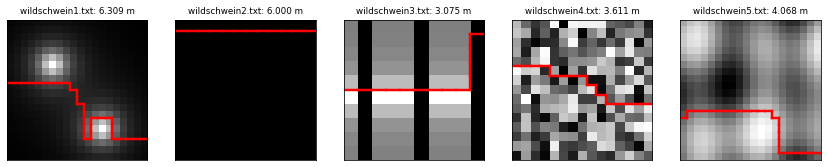

In [ ]:
HINWEISE = {1: (6.931, 6.287, 6.064), 2: (6.000, 6.000, 6.000), 3: (3.625, 3.075, 3.075),
            4: (3.635, 3.517, 3.451), 5: (4.645, 4.108, 4.065)}
print('Beispiel           Schranke  V1      V2      V3      V4     | Graph   Parallel MILP')
for nr in range(1, 6):
    g, p, m = HINWEISE[nr]
    print('wildschwein%d.txt   %.4f  %.4f  %.4f  %.4f  %.4f | %.3f   %.3f    %.3f' %
          (nr, schranke[nr], ergebnis_v1[nr], ergebnis_v2[nr], ergebnis_v3[nr], ergebnis_v4[nr][0], g, p, m))
print()
for nr in range(1, 6):
    print('wildschwein%d.txt: %.4f m Erde, also %.2f Euro' % (nr, ergebnis_v4[nr][0], 100 * ergebnis_v4[nr][0]))

fig, achsen = plt.subplots(1, 5, figsize=(15, 3.4))
for nr in range(1, 6):
    zeichne(achsen[nr - 1], felder[nr], 'wildschwein%d.txt: %.3f m' % (nr, ergebnis_v4[nr][0]), ergebnis_v4[nr][1])
plt.show()

**Ehrlicher Vergleich:**

- `wildschwein2.txt` und `wildschwein3.txt` lösen wir **optimal** (die Schranke beweist es).
- Bei `wildschwein5.txt` (4,0680 m) sind wir besser als „Parallel-Graph“ (4,108 m) und nur 0,003 m schlechter als CPLEX (4,065 m).
- Bei `wildschwein1.txt` (6,3090 m) sind wir deutlich besser als „Graph“ (6,931 m), aber etwas schlechter als „Parallel-Graph“
  (6,287 m) und CPLEX (6,064 m). Mit anderen Zufallszahlen kommt hier etwas anderes heraus, mal etwas besser, mal etwas schlechter.
- Bei `wildschwein4.txt` (3,6105 m) sind wir nur wenig besser als „Graph“ (3,635 m), aber schlechter als „Parallel-Graph“ (3,517 m)
  und CPLEX (3,451 m). Die Brache ist fast eben mit kleinen Unterschieden, viele Pfade sind fast gleich teuer, und unsere Ausführung nur
  entlang der Pfadlinien lässt hier etwas liegen (mehr dazu im MiniZinc-Abschnitt).
- Die untere Schranke ist bei den Beispielen 1, 4 und 5 viel kleiner als alle bekannten Lösungen; sie ist dort zu grob, um mehr zu sagen.

**Die Erdarbeiten.** Die Aufgabe fragt nach den Erdarbeiten, nicht nur nach den Kosten. `zeige_arbeiten` gibt sie nach Menge sortiert in
Zentimetern aus (Zeile 0 ist die Nordgrenze, Spalte 0 der Westzaun). Für `wildschwein3.txt` zeigen wir alle, für die anderen Beispiele nur
die fünf größten.

In [ ]:
def zeige_arbeiten(arbeiten, hoechstens):
    sortiert = []
    for von, nach, menge in arbeiten:
        sortiert.append((menge, von, nach))
    sortiert.sort()
    sortiert.reverse()
    for menge, von, nach in sortiert[:hoechstens]:
        print('  von Feld %-8s nach Feld %-8s %6.2f cm' % (von, nach, 100 * menge))
    if len(sortiert) > hoechstens:
        print('  ... und %d weitere' % (len(sortiert) - hoechstens))


for nr in range(1, 6):
    kosten, linien, arbeiten = ergebnis_v4[nr]
    print('wildschwein%d.txt: %d Erdarbeiten, zusammen %.2f cm = %.2f Euro' % (nr, len(arbeiten), 100 * kosten, 100 * kosten))
    zeige_arbeiten(arbeiten, 20 if nr == 3 else 5)

wildschwein1.txt: 20 Erdarbeiten, zusammen 630.90 cm = 630.90 Euro
  von Feld (9, 8)   nach Feld (9, 9)    62.35 cm
  von Feld (12, 10) nach Feld (11, 10)  57.35 cm
  von Feld (10, 9)  nach Feld (10, 10)  52.85 cm
  von Feld (17, 19) nach Feld (16, 19)  47.95 cm
  von Feld (9, 0)   nach Feld (8, 0)    47.85 cm
  ... und 15 weitere
wildschwein2.txt: 12 Erdarbeiten, zusammen 600.00 cm = 600.00 Euro
  von Feld (1, 11)  nach Feld (0, 11)   50.00 cm
  von Feld (1, 10)  nach Feld (0, 10)   50.00 cm
  von Feld (1, 9)   nach Feld (0, 9)    50.00 cm
  von Feld (1, 8)   nach Feld (0, 8)    50.00 cm
  von Feld (1, 7)   nach Feld (0, 7)    50.00 cm
  ... und 7 weitere
wildschwein3.txt: 10 Erdarbeiten, zusammen 307.50 cm = 307.50 Euro
  von Feld (5, 5)   nach Feld (4, 5)    50.00 cm
  von Feld (5, 1)   nach Feld (4, 1)    50.00 cm
  von Feld (1, 9)   nach Feld (0, 9)    50.00 cm
  von Feld (4, 8)   nach Feld (5, 8)    22.50 cm
  von Feld (4, 7)   nach Feld (5, 7)    22.50 cm
  von Feld (4, 6)   nac

## Für Neugierige

**Warum genügt eine Sperre vom West- zum Ostzaun?** Die Felder, die die Wildschweine von Norden aus erreichen, bilden ein zusammenhängendes
Gebiet. Kommen sie nicht bis zur Südgrenze, ist der südliche Rand dieses Gebiets eine Kette von kritischen Linien, die von Zaun zu Zaun
reicht. Umgekehrt muss jeder Weg von Norden nach Süden eine solche Kette irgendwo überqueren. Der Graph der Ecken ist der **duale Graph**
des Gitters: Wege im einen entsprechen Schnitten im anderen.

**Warum wird das Ausbessern fertig?** Bei zwei Linien an einem gemeinsamen Feld, die sich stören, bleibt nach jeder Ausbesserung die Hälfte
des Rests der anderen Linie übrig. Der Rest schrumpft also wie `1/2, 1/4, 1/8, …` und ist nach etwa 40 Schritten kleiner als ein
billionstel Meter. Bei mehr Linien geht es ähnlich, sicherheitshalber bricht `ausbessern` nach 10000 Schritten ab.

**Laufzeit.** Bei einer `n × n`-Brache hat der Graph der Ecken etwa `n²` Knoten und `2n²` Kanten. Dijkstra mit einer Warteschlange braucht
etwa `n² · log n` Schritte, das Ausführen ist bei Pfaden mit höchstens `n²` Linien noch schneller. Für Version 4 kommt die Zahl der Versuche
als Faktor hinzu.

**Was fehlt uns?** Wir bewegen Erde nur zwischen den beiden Feldern einer Linie des Pfades. Erde von einem dritten Feld zu holen, über
mehrere Felder zu tragen oder ganz andere Formen der Sperre zu bauen, betrachten wir nicht. Das schafft erst ein Optimierungsmodell wie
das MILP der Lösungshinweise; im nächsten Abschnitt bauen wir eine kleine Fassung davon.

## Zum Schluss: Die besten Erdarbeiten für einen Pfad mit MiniZinc

Wie viel verschenkt unsere Ausführung? Für einen **festen** Pfad kann ein Optimierer die besten Erdarbeiten berechnen, und dabei darf er
Erde zwischen **allen** Nachbarfeldern bewegen, auch über mehrere Felder hinweg. Das Modell:

- Für jedes Paar von Nachbarfeldern und jede Richtung gibt es eine Kommazahl-Variable (`var 0.0..2.0`) für die Erde, die dorthin gebracht
  wird. Die neue Höhe eines Feldes ist die alte plus alles, was hineinkommt, minus alles, was hinausgeht.
- Für jede Linie des Pfades entscheidet eine 0/1-Variable `erstes_hoeher`, welches Feld das höhere werden soll. Der Trick mit dem
  **großen M**: Ist `erstes_hoeher[i] = 1`, verlangt die erste Ungleichung `neu1 - neu2 ≥ 1`, und die zweite lautet `neu2 - neu1 ≥ 1 - 10`;
  sie ist immer erfüllt, weil kein Unterschied größer als 9 m wird. Bei `erstes_hoeher[i] = 0` ist es umgekehrt. So wird aus „mindestens
  1 m nach oben **oder** nach unten“ ein Paar von linearen Ungleichungen.
- Ziel: so wenig Erde wie möglich.
```minizinc
int: n;
array[1..n, 1..n] of float: h;            % Höhen in Metern
int: m;                                   % Zahl der Linien des Pfades
array[1..m] of 1..n: r1;                  % Linie i liegt zwischen den Feldern (r1[i], c1[i]) und (r2[i], c2[i])
array[1..m] of 1..n: c1;
array[1..m] of 1..n: r2;
array[1..m] of 1..n: c2;
float: M = 10.0;                          % größer als jeder mögliche Höhenunterschied

% Erde, die zwischen Nachbarfeldern bewegt wird (in Metern, beide Richtungen)
array[1..n-1, 1..n] of var 0.0..2.0: runter;    % von (r, c) nach (r + 1, c)
array[1..n-1, 1..n] of var 0.0..2.0: rauf;      % von (r + 1, c) nach (r, c)
array[1..n, 1..n-1] of var 0.0..2.0: rechts;    % von (r, c) nach (r, c + 1)
array[1..n, 1..n-1] of var 0.0..2.0: links;     % von (r, c + 1) nach (r, c)

array[1..n, 1..n] of var float: neu;      % Höhen nach den Erdarbeiten
constraint forall(r, c in 1..n)(
    neu[r, c] = h[r, c]
        - (if r < n then runter[r, c] - rauf[r, c] else 0.0 endif)
        + (if r > 1 then runter[r - 1, c] - rauf[r - 1, c] else 0.0 endif)
        - (if c < n then rechts[r, c] - links[r, c] else 0.0 endif)
        + (if c > 1 then rechts[r, c - 1] - links[r, c - 1] else 0.0 endif));

array[1..m] of var 0..1: erstes_hoeher;   % 1: das erste Feld der Linie wird das höhere
constraint forall(i in 1..m)(
    neu[r1[i], c1[i]] - neu[r2[i], c2[i]] >= 1 - M * (1 - erstes_hoeher[i]) /\
    neu[r2[i], c2[i]] - neu[r1[i], c1[i]] >= 1 - M * erstes_hoeher[i]);

var float: erde = sum(runter) + sum(rauf) + sum(rechts) + sum(links);
solve minimize erde;
output ["erde = ", show_float(1, 4, erde), " m\n"];
```

Weil das Modell Kommazahlen und nur Summen enthält, nehmen wir **HiGHS**, einen Solver für gemischt-ganzzahlige lineare Optimierung, der
bei MiniZinc dabei ist (Auswahl über *Solver configuration*). Chuffed und CP-SAT rechnen nur mit ganzen Zahlen. Die Datendatei
erzeugt `als_dzn` aus den Linien eines Pfades (in MiniZinc beginnen Zeilen und Spalten bei 1).

In [ ]:
def als_dzn(h, linien):
    n = len(h)
    zeilen = []
    for zeile in h:
        zeilen.append(', '.join('%.3f' % x for x in zeile))
    r1, c1, r2, c2 = [], [], [], []
    for a, b in linien:
        r1.append(a[0] + 1)
        c1.append(a[1] + 1)
        r2.append(b[0] + 1)
        c2.append(b[1] + 1)
    return ('n = %d;\nh = [|%s|];\nm = %d;\nr1 = %s;\nc1 = %s;\nr2 = %s;\nc2 = %s;' %
            (n, '\n     |'.join(zeilen), len(linien), r1, c1, r2, c2))


print(als_dzn(felder[3], ergebnis_v4[3][1])[:400], '...')

n = 10;
h = [|3.042, 2.000, 3.042, 3.042, 3.042, 2.000, 3.042, 3.042, 3.042, 2.000
     |3.065, 2.000, 3.065, 3.065, 3.065, 2.000, 3.065, 3.065, 3.065, 2.000
     |3.110, 2.000, 3.110, 3.110, 3.110, 2.000, 3.110, 3.110, 3.110, 2.000
     |3.220, 2.000, 3.220, 3.220, 3.220, 2.000, 3.220, 3.220, 3.220, 2.000
     |3.550, 2.000, 3.550, 3.550, 3.550, 2.000, 3.550, 3.550, 3.550, 2.000
     |4.100, 2.00 ...


**`wildschwein4.txt`** (HiGHS, Pfad aus Version 4):

**Ausgabe:**

```
erde = 3.5180 m
----------
==========
```

Bei allen fünf Beispielen ist HiGHS in weniger als einer Sekunde fertig und beweist, dass es für diesen Pfad nicht besser geht (gemessen beim
Erstellen dieses Notebooks):

| Beispiel | unsere Ausführung (V4) | beste Erdarbeiten für denselben Pfad | MILP der Hinweise |
|----------|------------------------|--------------------------------------|-------------------|
| `wildschwein1.txt` | 6,3090 m | 6,3090 m | 6,064 m |
| `wildschwein2.txt` | 6,0000 m | 6,0000 m | 6,000 m |
| `wildschwein3.txt` | 3,0750 m | 3,0750 m | 3,075 m |
| `wildschwein4.txt` | 3,6105 m | 3,5180 m | 3,451 m |
| `wildschwein5.txt` | 4,0680 m | 4,0680 m | 4,065 m |

Bei den Beispielen 1, 2, 3 und 5 ist unsere Ausführung für den gewählten Pfad schon optimal. Bei `wildschwein4.txt` holt HiGHS
0,093 m heraus und kommt auf 3,518 m, fast genau den Wert von „Parallel-Graph“ (3,517 m). Dafür bringt HiGHS auch Erde zwischen
Nachbarfeldern, die nicht durch eine Linie des Pfades getrennt sind; das kann unsere Ausführung nicht. Bei `wildschwein1.txt` liegt der
Abstand zu CPLEX (0,245 m) dagegen ganz am Pfad selbst: CPLEX wählt die Sperre und die Erdarbeiten **gemeinsam**.

**Und das ganze Problem?** Man kann auch die Sperre von MiniZinc suchen lassen: eine 0/1-Variable je Feld „ein Wildschwein kommt hin“
(Nordgrenze 1, Südgrenze 0, und über eine nicht kritische Linie kommt es weiter) und eine 0/1-Variable je Linie „kritisch“. Beim Erstellen
dieses Notebooks fand HiGHS damit in 60 Sekunden bei `wildschwein3.txt` die optimalen 3,075 m (ohne den Beweis), bei `wildschwein1.txt`
aber nur 7,860 m, bei `wildschwein4.txt` 4,746 m und bei `wildschwein5.txt` gar keine Lösung. CP-SAT (in halben Millimetern gerechnet)
fand bei `wildschwein4.txt` in 60 Sekunden überhaupt keine Lösung. Auch CPLEX hat bei den Lösungshinweisen nach
Stunden abgebrochen. Das Zusammenspiel von Graphensuche für die Sperre und Optimierer für die Erdarbeiten ist hier der bessere Weg.